In [2]:
import sys
from pathlib import Path

# Encontra o módulo e disponibiliza seu pacote Python, sem depender da pasta atual.
PASTA_ATUAL = Path.cwd().resolve()
PASTA_PROJETO = next(
    (
        pasta
        for base in (PASTA_ATUAL, *PASTA_ATUAL.parents)
        for pasta in (
            base,
            base / "04_regressao_polinomial",
            base / "regressao_modelos_lineares" / "04_regressao_polinomial",
        )
        if (pasta / "src" / "polinomial" / "config.py").is_file()
    ),
    None,
)
if PASTA_PROJETO is None:
    raise FileNotFoundError("Não foi possível localizar o módulo 04_regressao_polinomial.")
PASTA_SRC = PASTA_PROJETO / "src"
if str(PASTA_SRC) not in sys.path:
    sys.path.insert(0, str(PASTA_SRC))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.preprocessing import (
    OrdinalEncoder,
    OneHotEncoder,
    PolynomialFeatures,
    PowerTransformer,
    StandardScaler,
    QuantileTransformer,
)

from polinomial.auxiliares import dataframe_coeficientes
from polinomial.config import DADOS_DIABETES_CATEGORIZADOS
from polinomial.graficos import plot_comparar_metricas_modelos, plot_coeficientes
from polinomial.modelos import RANDOM_STATE
from polinomial.modelos import grid_search_cv_regressor, organiza_resultados, treinar_e_validar_modelo_regressao

sns.set_theme(palette="bright")

In [3]:
df = pd.read_parquet(DADOS_DIABETES_CATEGORIZADOS)

df.head()

,idade,sexo,imc,pressao_media,colesterol_total,ldl,hdl,triglicerides,glicose,target,colesterol_hdl_cat
0,59,2,32.099998,101.0,157,93.199997,38.0,4.8598,87,151,4-5
1,48,1,21.600000,87.0,183,103.199997,70.0,3.8918,69,75,2-3
2,72,2,30.500000,93.0,156,93.599998,41.0,4.6728,85,141,4-5
3,24,1,25.299999,84.0,198,131.399994,40.0,4.8903,89,206,4-5
4,50,1,23.000000,101.0,192,125.400002,52.0,4.2905,80,135,4-5


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   idade               442 non-null    int8    
 1   sexo                442 non-null    int8    
 2   imc                 442 non-null    float32 
 3   pressao_media       442 non-null    float32 
 4   colesterol_total    442 non-null    int16   
 5   ldl                 442 non-null    float32 
 6   hdl                 442 non-null    float32 
 7   triglicerides       442 non-null    float32 
 8   glicose             442 non-null    int8    
 9   target              442 non-null    int16   
 10  colesterol_hdl_cat  442 non-null    category
dtypes: category(1), float32(5), int16(2), int8(3)
memory usage: 12.3 KB


In [5]:
X = df.drop(columns="target")
y = df["target"]

In [6]:
colunas_power_transform = ["imc", "ldl", "hdl", "colesterol_total"]

coluna_target = ["target"]

coluna_ordinal_encoder = ["colesterol_hdl_cat"]

coluna_one_hot_encoder = ["sexo"]

colunas_standard_scaler = [
    coluna
    for coluna in df.columns
    if coluna not in colunas_power_transform + coluna_target + coluna_ordinal_encoder + coluna_one_hot_encoder
]

colunas_standard_scaler

['idade', 'pressao_media', 'triglicerides', 'glicose']

In [7]:
categorias_ordinal_encoder = [
    ["2-3", "4-5", "6+"],
]

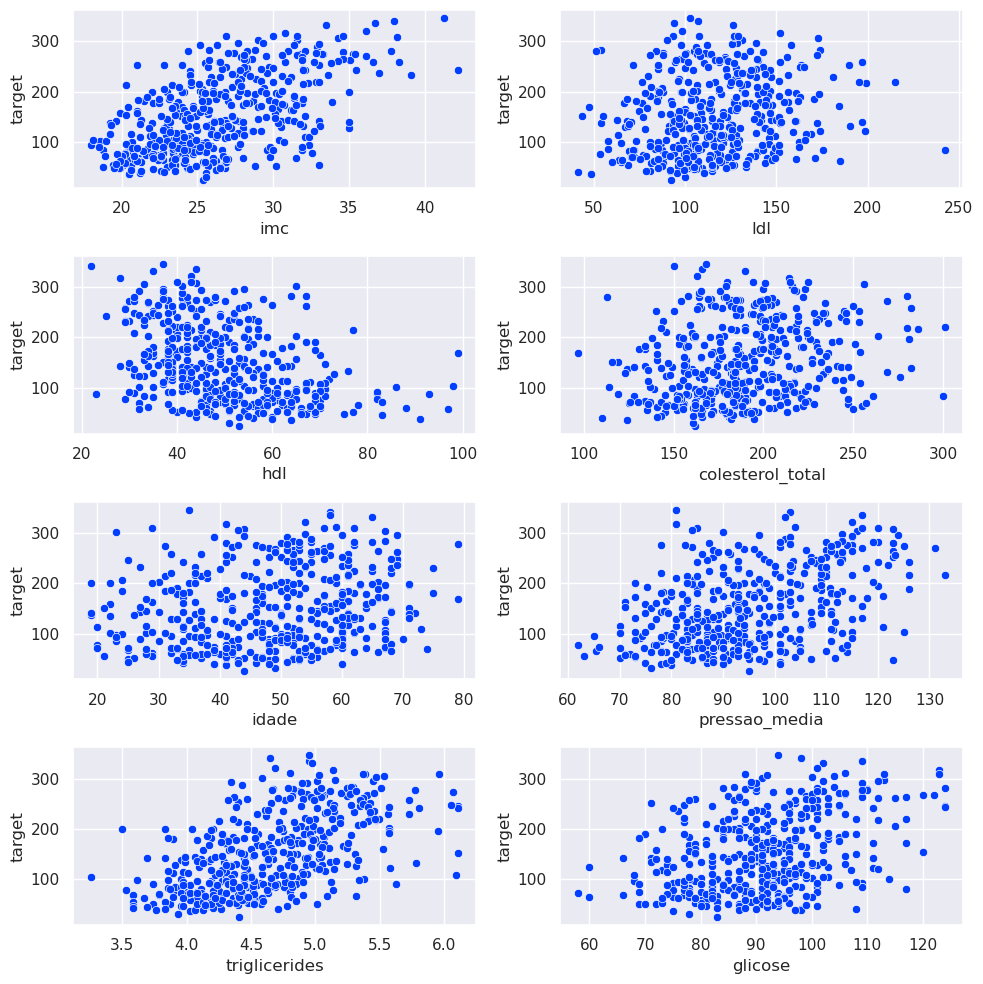

In [8]:
fig, axs = plt.subplots(4, 2, figsize=(10, 10))

for ax, coluna in zip(axs.flatten(), colunas_power_transform + colunas_standard_scaler):
    sns.scatterplot(x=coluna, y="target", data=df, ax=ax)

plt.tight_layout()

plt.show()

In [9]:
preprocessamento_categoricas = ColumnTransformer(
    transformers=[
        ("ordinal_encoder", OrdinalEncoder(categories=categorias_ordinal_encoder), coluna_ordinal_encoder),
        ("one_hot_encoder", OneHotEncoder(drop="if_binary"), coluna_one_hot_encoder),
    ],
    remainder="passthrough",
)

preprocessamento_simples = ColumnTransformer(
    transformers=[
        ("ordinal_encoder", OrdinalEncoder(categories=categorias_ordinal_encoder), coluna_ordinal_encoder),
        ("one_hot_encoder", OneHotEncoder(drop="if_binary"), coluna_one_hot_encoder),
        ("standard_scaler", StandardScaler(), X.columns.difference(coluna_ordinal_encoder + coluna_one_hot_encoder)),
    ],
    remainder="passthrough",
)

preprocessamento_completo = ColumnTransformer(
    [
        ("power_transform", PowerTransformer(method="box-cox"), colunas_power_transform),
        ("standard_scaler", StandardScaler(), colunas_standard_scaler),
        ("ordinal_encoder", OrdinalEncoder(categories=categorias_ordinal_encoder), coluna_ordinal_encoder),
        ("one_hot_encoder", OneHotEncoder(drop="if_binary"), coluna_one_hot_encoder),
    ]
)

target_transformer = QuantileTransformer(n_quantiles=20, output_distribution="normal")

In [10]:
elasticnet_regressor = ElasticNet()

In [11]:
param_grid = {
    "regressor__reg__alpha": [1E-2, 5E-2, 0.1, 1.0, 5.0, 10],
    "regressor__reg__l1_ratio": [0.1, 0.25, 0.5, 0.75, 0.9],
    "regressor__preprocessor__power__transform_poly__poly__degree": [1, 2, 3],
    "regressor__preprocessor__power__standard_scaler_poly__poly__degree": [1, 2, 3],
    "transformer": [target_transformer, None]
}

In [12]:
grid_search = grid_search_cv_regressor(
    regressor=elasticnet_regressor,
    param_grid=param_grid,
    preprocessor=preprocessamento_categoricas,
    target_transformer=target_transformer,
)

grid_search

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             error_score='raise',
             estimator=TransformedTargetRegressor(regressor=Pipeline(steps=[('preprocessor',
                                                                             ColumnTransformer(remainder='passthrough',
                                                                                               transformers=[('ordinal_encoder',
                                                                                                              OrdinalEncoder(categories=[['2-3',
                                                                                                                                          '4-5',
                                                                                                                                          '6+']]),
                                                                                                              ['colesterol_hdl_cat']),
                                                                                                             ('one_hot_encoder',
                                                                                                              OneHotEncoder(drop='if...
                         'regressor__preprocessor__power__transform_poly__poly__degree': [1,
                                                                                          2,
                                                                                          3],
                         'regressor__reg__alpha': [0.01, 0.05, 0.1, 1.0, 5.0,
                                                   10],
                         'regressor__reg__l1_ratio': [0.1, 0.25, 0.5, 0.75,
                                                      0.9],
                         'transformer': [QuantileTransformer(n_quantiles=20,
                                                             output_distribution='normal'),
                                         None]},
             refit='neg_root_mean_squared_error',
             scoring=['r2', 'neg_mean_absolute_error',
                      'neg_root_mean_squared_error'],
             verbose=1)

In [ ]:
grid_search.fit(X, y) 

Fitting 5 folds for each of 540 candidates, totalling 2700 fits


ValueError: Invalid parameter 'power' for estimator ColumnTransformer(remainder='passthrough',
                  transformers=[('ordinal_encoder',
                                 OrdinalEncoder(categories=[['2-3', '4-5',
                                                             '6+']]),
                                 ['colesterol_hdl_cat']),
                                ('one_hot_encoder',
                                 OneHotEncoder(drop='if_binary'), ['sexo'])]). Valid parameters are: ['force_int_remainder_cols', 'n_jobs', 'remainder', 'sparse_threshold', 'transformer_weights', 'transformers', 'verbose', 'verbose_feature_names_out'].

In [ ]:
grid_search.best_params_

In [ ]:
grid_search.best_score_

In [ ]:
grid_search.best_estimator_

In [ ]:
print(*grid_search.cv_results_.keys(), sep="\n")

In [ ]:
max(grid_search.cv_results_["mean_test_neg_root_mean_squared_error"])

In [ ]:
grid_search.best_estimator_

In [ ]:
grid_search.best_estimator_.regressor_["preprocessor"]

In [ ]:
grid_search.best_estimator_.regressor_["reg"]

In [ ]:
grid_search.best_estimator_.transformer_

In [ ]:
grid_search.best_estimator_.regressor_["reg"].coef_

In [ ]:
grid_search.best_estimator_.regressor_["reg"].intercept_

In [ ]:
grid_search.best_estimator_.regressor_["preprocessor"].get_feature_names_out()

In [ ]:
coefs = dataframe_coeficientes(
    grid_search.best_estimator_.regressor_["reg"].coef_,
    grid_search.best_estimator_.regressor_["preprocessor"].get_feature_names_out()
)

coefs

In [ ]:
plot_coeficientes(coefs, "ElasticNet com StdSc, OE, OHE")

In [ ]:
regressors = {
    "DummyRegressor": {
        "preprocessor": None,
        "regressor": DummyRegressor(strategy="mean"),
        "target_transformer": None,
    },
    
    "LinearRegression_pre_simples": {
        "preprocessor": preprocessamento_simples,
        "regressor": LinearRegression(),
        "target_transformer": None,
    },
    "ElasticNet_grid_search": {
        "preprocessor": grid_search.best_estimator_.regressor_["preprocessor"],
        "regressor": grid_search.best_estimator_.regressor_["reg"],
        "target_transformer": grid_search.best_estimator_.transformer_,
    },
}

In [ ]:
resultados = {
    nome_modelo: treinar_e_validar_modelo_regressao(X, y, **regressor)
    for nome_modelo, regressor in regressors.items()
}

resultados

In [ ]:
df_resultados = organiza_resultados(resultados)

df_resultados

In [ ]:
plot_comparar_metricas_modelos(df_resultados)